In [1]:
import pandas as pd
import numpy as np

In [3]:
# AT = Temperature
# v  = Vaccume
# AP = pressure
# RH = Humidity
# PE = Produced Energy

df = pd.read_csv("powerplant_data.csv")
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [5]:
X = df.drop(columns=["PE"])
y = df["PE"]

In [6]:
# Split out the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

In [9]:
import torch
import torch.nn as nn

X_train_tensors = torch.tensor(X_train_scale, dtype=torch.float32 )
X_test_tensors = torch.tensor(X_test_scale, dtype=torch.float32 )

In [10]:
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

In [11]:
from torch.utils.data import TensorDataset, DataLoader


train_dataset = TensorDataset(X_train_tensors, y_train_tensor)
test_dataset = TensorDataset(X_test_tensors, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [12]:
# Define ANN Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
        
            # 1st Hidden
            nn.Linear(X_train.shape[1], 6),  
            nn.ReLU(),

            # 2nd Hidden
            nn.Linear(6, 6), 
            nn.ReLU(),

            # output layer
            nn.Linear(6,1),   
        )

    # def function for the forward direction
    def forward(self, x):
        return self.model(x)
        

In [13]:
# Now define Loss and optimizer
import torch.optim as optimizer

model = ANN()

# loss
crietrion = nn.MSELoss()
# optimizer
optimizer = optimizer.Adam(model.parameters()) 

In [ ]:
# train the ANN
train_losses = []
val_losses = []

best_val_loss = float("inf")

epochs = 100
for epoch in range(epochs):
    model.train()

    running_loss = 0.0 

    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch

        optimizer.zero_grad() 

        outputs = model(xb) 
        loss = crietrion(outputs, yb) 
        loss.backward() 
        optimizer.step() 

        running_loss += loss.item()

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): 
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")




    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") 

epoch 1/100 ==> train loss = 204881.322265625 & val loss = 200683.46875
epoch 2/100 ==> train loss = 187924.68092447918 & val loss = 168727.203125
epoch 3/100 ==> train loss = 139691.4498046875 & val loss = 107007.671875
epoch 4/100 ==> train loss = 76134.11306966146 & val loss = 49115.4921875
epoch 5/100 ==> train loss = 33721.230721028645 & val loss = 23292.166015625
epoch 6/100 ==> train loss = 19029.23727010091 & val loss = 15901.9326171875
epoch 7/100 ==> train loss = 14158.118986002604 & val loss = 12278.185546875
epoch 8/100 ==> train loss = 10939.396901448568 & val loss = 9427.4365234375
epoch 9/100 ==> train loss = 8288.583190917969 & val loss = 6984.18896484375
epoch 10/100 ==> train loss = 5992.707656860352 & val loss = 4891.07373046875
epoch 11/100 ==> train loss = 4090.607450358073 & val loss = 3252.00048828125
epoch 12/100 ==> train loss = 2674.337099202474 & val loss = 2084.31298828125
epoch 13/100 ==> train loss = 1700.987497329712 & val loss = 1314.452392578125
epoch 1

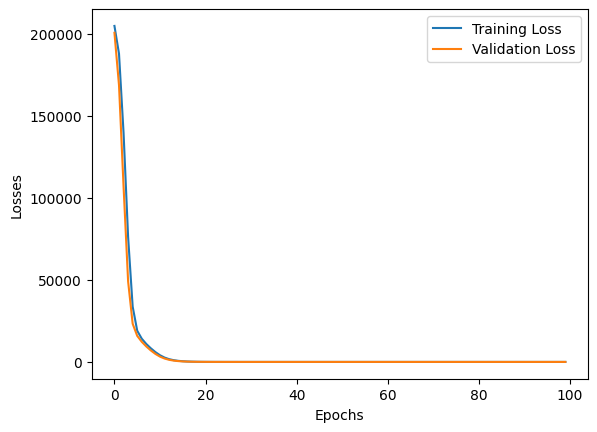

In [15]:
import matplotlib.pyplot as plt 

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.plot(loss_df["Training Loss"], label="Training Loss")
plt.plot(loss_df["Validation Loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()


In [16]:
# Loading the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [17]:
# Evaluation

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensors)
    test_preds = model(X_test_tensors)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 20.460275650024414
Testing MSE: 18.661251068115234


In [18]:
from sklearn.metrics import r2_score

print("r^2 score =", r2_score(y_test, test_preds))

r^2 score = 0.9347837449344898


In [19]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.121002,433.27
1,436.737061,438.16
2,461.024414,458.42
3,475.947235,480.82
4,435.188568,441.41
...,...,...
1909,451.083954,456.70
1910,431.458710,438.04
1911,467.407135,467.80
1912,430.904755,437.14
